# SEM / observed-variable path analysis
Operating conditions → Re/Rct → ln(SOH), with direct condition paths and valid cycle as control.
The original theoretical model is retained. Associations do not identify causal mediation.
Historical source/output copies in `reports/audit/regression_sem_before/` are optional comparisons.
Primary SEM, sensitivities, 200-valid battery bootstrap and diagram run without those archives; absence is reported explicitly.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/cycles_clean.csv').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start within this repository; processed cycles table not found')
sys.path.insert(0, str(PROJECT_ROOT/'src'))
from regression_sem_utils import load_cycles, regression_data, environment_manifest
np.random.seed(42)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)
print('Project:', PROJECT_ROOT)
print('Versions:', environment_manifest()['packages'])

Project: C:\Users\Admin\OneDrive\Tài liệu\HK1-Nam 3\PTTK\Project\STAT3013.R11.CTTT_Group08
Versions: {'numpy': '2.4.6', 'pandas': '3.1.1', 'scipy': '1.17.1', 'matplotlib': '3.11.2', 'statsmodels': '0.15.0', 'scikit-learn': '1.9.1', 'semopy': '2.3.11', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'ipykernel': '7.4.0'}


## Data availability and measurement audit
Tier A/B, first retained discharge linked to each distinct EIS operation. Join back to the actual EIS table,
require raw Re/Rct in (0, 0.5) ohm, and verify operation/time precedes discharge. This avoids treating a forward-filled value as a new observation.
The historical primary sample retains quality flags to preserve the specified SEM sample; excluding them is a reported sensitivity.
Missingness is reported before complete-case filtering. A newly linked EIS operation need not be immediately adjacent in physical time;
unlinked intermediate EIS operations cannot be reconstructed as SOH observations. EIS temperature and discharge ambient differ for cold cells.

In [2]:
from sem_analysis import prepare_sem
sem_data, sample_flow = prepare_sem(load_cycles())
display(sample_flow)
display(sem_data[['battery_id','cycle_valid','eis_op_index','Re_ohm','Rct_ohm','soh']].head())
display(sem_data.groupby(['ambient_C','I_level_A','discharge_cutoff_V']).battery_id.nunique().rename('batteries').reset_index())

,stage,n
0,Tier A/B cycle rows,2020
1,Distinct linked EIS operations,812
2,Raw EIS invalid or missing,0
3,Analysis complete cases,812
4,Independent battery blocks,22
5,Cleaned/raw resistance mismatches replaced,0
6,Flagged rows retained in historical/theory sample,14


,battery_id,cycle_valid,eis_op_index,Re_ohm,Rct_ohm,soh
0,B0005,20,40.0,0.044669,0.069456,1.000365
1,B0005,21,44.0,0.044843,0.067972,1.000573
2,B0005,22,48.0,0.045101,0.068528,0.994515
3,B0005,23,52.0,0.044172,0.068044,0.988926
4,B0005,24,56.0,0.043787,0.068450,0.988532


,ambient_C,I_level_A,discharge_cutoff_V,batteries
0,4.0,1.0,2.0,1
1,4.0,1.0,2.2,1
2,4.0,1.0,2.5,1
3,4.0,1.0,2.7,1
4,4.0,2.0,2.0,1
5,4.0,2.0,2.5,1
6,4.0,2.0,2.7,1
7,24.0,2.0,2.2,1
8,24.0,2.0,2.5,2
9,24.0,2.0,2.7,3


## Specification, convergence and fit audit
MLW/SLSQP fits the covariance structure; no latent variables or mean structure are introduced.
Primary theory paths match the original. All exogenous variances/covariances are explicitly free nuisance parameters.
`semopy` otherwise fixes these moments empirically without counting them in its df formula: the historical 13 df overstates the testable restrictions.
Standardizing internally improves conditioning; unstandardized coefficients and SEs are converted back to °C, A, V, cycles and ohm.
The numerical information rank, sample covariance rank, optimizer convergence and fitted covariance are checked.
Sensitivity 1 adds age → Re/Rct because resistance ages; sensitivity 2 adds Re ~~ Rct because they share measurement and chemistry.
The latter is saturated (zero df): no overall-fit claim is supported. No path is chosen by a modification-index search.
Conventional chi-square/p-values and fit indices assume independent rows, so clustered data make them descriptive diagnostics.
The primary model remains the original theory; fit failures are disclosed rather than optimized away.

Historical specification: 
Re_ohm ~ ambient_C + I_level_A + discharge_cutoff_V
Rct_ohm ~ ambient_C + I_level_A + discharge_cutoff_V
ln_soh ~ Re_ohm + Rct_ohm + ambient_C + I_level_A + discharge_cutoff_V + cycle_valid

Primary specification: 
Re_ohm ~ ambient_C + I_level_A + discharge_cutoff_V
Rct_ohm ~ ambient_C + I_level_A + discharge_cutoff_V
ln_soh ~ Re_ohm + Rct_ohm + ambient_C + I_level_A + discharge_cutoff_V + cycle_valid
ambient_C ~~ ambient_C
I_level_A ~~ I_level_A
discharge_cutoff_V ~~ discharge_cutoff_V
cycle_valid ~~ cycle_valid
ambient_C ~~ I_level_A
ambient_C ~~ discharge_cutoff_V
ambient_C ~~ cycle_valid
I_level_A ~~ discharge_cutoff_V
I_level_A ~~ cycle_valid
discharge_cutoff_V ~~ cycle_valid
legacy_raw_units_reexecution {'n': 812, 'DoF': 13.0, 'chi2': 5068.96752425383, 'CFI': 0.49005533322102846, 'TLI': 0.019337179271208503, 'RMSEA': 0.6925004095657811, 'information_rank': 15, 'free_parameters': 15}


original_scaled_implicit_exog {'n': 812, 'DoF': 13.0, 'chi2': 479.28989440426335, 'CFI': 0.8547468739040719, 'TLI': 0.7206670652001382, 'RMSEA': 0.2103032084320975, 'information_rank': 15, 'free_parameters': 15}


primary_explicit_exog {'n': 812, 'DoF': 3.0, 'chi2': 479.289894414195, 'CFI': 0.8518164334769776, 'TLI': -0.037284965661157424, 'RMSEA': 0.44245043769066067, 'information_rank': 25, 'free_parameters': 25}


age_control_sensitivity {'n': 812, 'DoF': 1.0, 'chi2': 341.74116032946966, 'CFI': 0.8939884280750572, 'TLI': -1.226243010423799, 'RMSEA': 0.6481893212741907, 'information_rank': 27, 'free_parameters': 27}


age_correlated_residuals_SATURATED {'n': 812, 'DoF': 0.0, 'chi2': 3.906420609212091e-08, 'CFI': nan, 'TLI': nan, 'RMSEA': nan, 'information_rank': 28, 'free_parameters': 28}


exclude_quality_flags_sensitivity {'n': 798, 'DoF': 3.0, 'chi2': 460.5825774166245, 'CFI': 0.8677359393386829, 'TLI': 0.07415157537077997, 'RMSEA': 0.4374666516138175, 'information_rank': 25, 'free_parameters': 25}


Bootstrap: 50 valid / 50 attempts


Bootstrap: 100 valid / 100 attempts


Bootstrap: 150 valid / 150 attempts


Bootstrap: 200 valid / 200 attempts


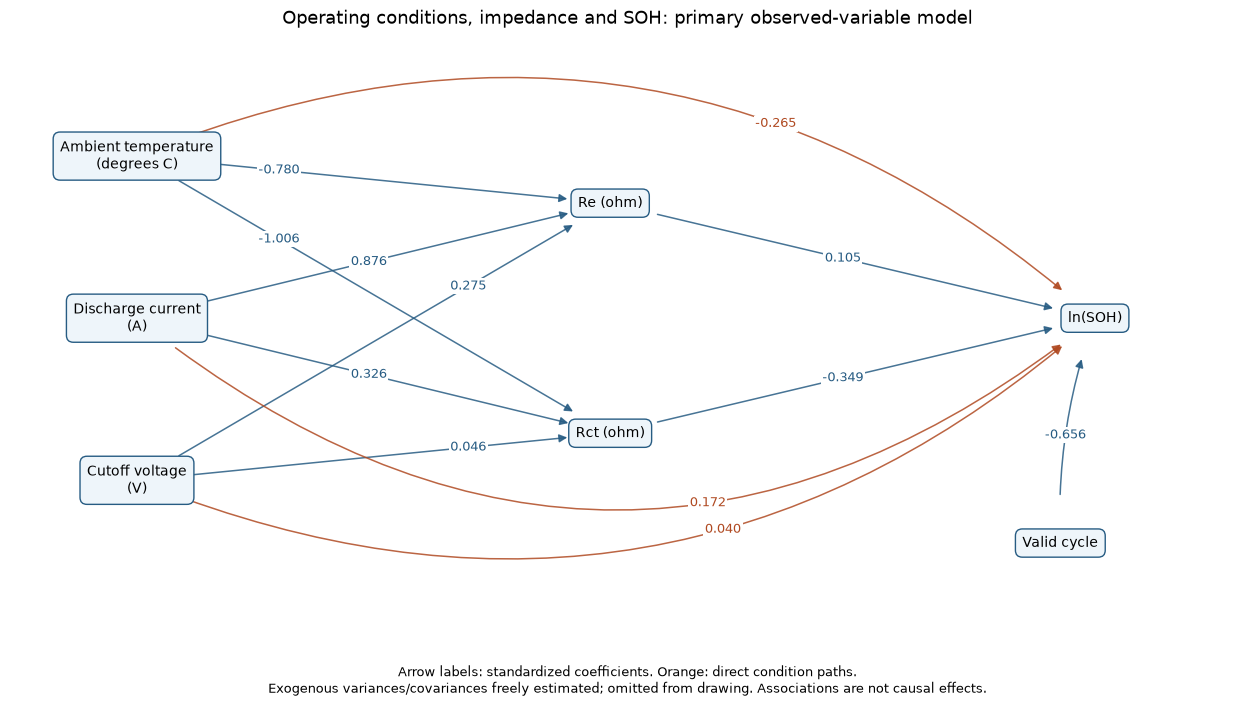

,model,converged,iterations,objective,free_parameters,information_rank,observed_moments,DoF,DoF Baseline,chi2,chi2 p-value,chi2 Baseline,CFI,GFI,AGFI,NFI,TLI,RMSEA,AIC,BIC,LogLik,n,batteries
0,legacy_raw_units_reexecution,True,77,6.242571e+00,15,15,28,13.0,25.0,5.068968e+03,0.0,9939.737527,0.490055,0.490030,0.019289,0.490030,0.019337,0.692500,17.514858,88.007363,6.242571e+00,812,22
1,original_scaled_implicit_exog,True,27,5.902585e-01,15,15,28,13.0,25.0,4.792899e+02,0.0,3235.188358,0.854747,0.851851,0.715098,0.851851,0.720667,0.210303,28.819483,99.311988,5.902585e-01,812,22
2,primary_explicit_exog,True,27,5.902585e-01,25,25,28,3.0,21.0,4.792899e+02,0.0,3235.188358,0.851816,0.851851,-0.037043,0.851851,-0.037285,0.442450,48.819483,166.306992,5.902585e-01,812,22
3,age_control_sensitivity,True,29,4.208635e-01,27,27,28,1.0,21.0,3.417412e+02,0.0,3235.188358,0.893988,0.894367,-1.218283,0.894367,-1.226243,0.648189,53.158273,180.044782,4.208635e-01,812,22
4,age_correlated_residuals_SATURATED,True,29,4.810863e-11,28,28,28,0.0,21.0,3.906421e-08,NaN,3235.188358,NaN,1.000000,NaN,1.000000,NaN,NaN,56.000000,187.586010,4.810863e-11,812,22
5,exclude_quality_flags_sensitivity,True,26,5.771711e-01,25,25,28,3.0,21.0,4.605826e+02,0.0,3480.613860,0.867736,0.867672,0.073704,0.867672,0.074152,0.437467,48.845658,165.898373,5.771711e-01,798,22


,lval,op,rval,Estimate,Est. Std,Std. Err,z-value,p-value,Estimate_optimizer_scale,CI_low_iid,CI_high_iid,bootstrap_SE,bootstrap_CI_low,bootstrap_CI_high,standardized_CI_low,standardized_CI_high
0,Re_ohm,~,ambient_C,-0.002018,-0.779668,0.000078,-25.797185,0.000000e+00,-0.779667,-0.002171,-0.001865,0.000387,-0.002687,-0.001188,-1.201614,-0.505954
1,Re_ohm,~,I_level_A,0.022592,0.875544,0.000847,26.672711,0.000000e+00,0.875544,0.020932,0.024253,0.005940,0.009231,0.030850,0.319609,1.258241
2,Re_ohm,~,discharge_cutoff_V,0.025306,0.275420,0.002530,10.004112,0.000000e+00,0.275420,0.020348,0.030264,0.017559,-0.002490,0.058890,-0.023212,0.655067
3,Rct_ohm,~,ambient_C,-0.005190,-1.005578,0.000112,-46.257431,0.000000e+00,-1.005578,-0.005410,-0.004970,0.000723,-0.006543,-0.003645,-1.162047,-0.807784
4,Rct_ohm,~,I_level_A,0.016782,0.326152,0.001215,13.813780,0.000000e+00,0.326152,0.014401,0.019163,0.008588,-0.004299,0.028242,-0.061777,0.650536
5,Rct_ohm,~,discharge_cutoff_V,0.008356,0.045608,0.003628,2.303161,2.126980e-02,0.045608,0.001245,0.015467,0.030356,-0.045176,0.064328,-0.248139,0.353584
6,ln_soh,~,Re_ohm,0.697199,0.104717,0.242070,2.880150,3.974857e-03,0.106607,0.222750,1.171648,2.369535,-6.029676,3.153285,-0.704870,0.556180
7,ln_soh,~,Rct_ohm,-1.165717,-0.349127,0.168778,-6.906810,4.956702e-12,-0.355428,-1.496516,-0.834918,0.508586,-1.789717,0.148335,-0.724353,0.045620
8,ln_soh,~,ambient_C,-0.004559,-0.264563,0.001146,-3.979498,6.906106e-05,-0.269338,-0.006805,-0.002314,0.005372,-0.016861,0.002214,-1.039629,0.200127
9,ln_soh,~,I_level_A,0.029552,0.172011,0.008522,3.467803,5.247309e-04,0.175116,0.012849,0.046254,0.053572,-0.032356,0.154452,-0.198025,0.976285


In [3]:
from sem_analysis import ORIGINAL, PRIMARY, AGE_CONTROL, SATURATED, run_sem
print('Historical specification:', ORIGINAL)
print('Primary specification:', PRIMARY)
sem_results = run_sem(sem_data)
display(sem_results['fit'])
display(sem_results['coefficients'])

## Battery-block bootstrap and path products
Seed 42; sample 22 complete batteries with replacement, including multiplicities. Continue until 200 valid fits (maximum 500 attempts).
Reject explicit solver failures, nonfinite estimates, rank-deficient covariance and nonpositive fitted variance; retain an attempt log.
Bootstrap CIs are percentiles, with separate Re and Rct indirect associations and direct/combined/total effects.
For an original-unit change in a condition, products are on the ln(SOH) scale. No unstable percent-mediated ratio is calculated.
Internal standardization is recomputed per resample and all effects are returned to original units before taking percentiles.
The primary 320-dpi diagram labels actual **standardized** fitted coefficients. Conventional IID SE/p-values are distinguished from block-bootstrap intervals.

In [4]:
print('Bootstrap:', sem_results['bootstrap'])
display(sem_results['effects'])
display(sem_results['intervals'])

Bootstrap: {'seed': 42, 'target_valid': 200, 'valid': 200, 'attempts': 200, 'failures': 0, 'failure_reasons': {}}


,predictor,direct,indirect_via_Re,indirect_via_Rct,indirect_combined,total
0,ambient_C,-0.004559,-0.001407,0.006050,0.004643,0.000084
1,I_level_A,0.029552,0.015751,-0.019563,-0.003811,0.025740
2,discharge_cutoff_V,0.024711,0.017644,-0.009741,0.007903,0.032614


,predictor,effect,bootstrap_SE,CI_low,CI_high,excludes_zero,valid_replicates
0,I_level_A,direct,0.053572,-0.032356,0.154452,False,200
1,I_level_A,indirect_via_Re,0.045868,-0.101672,0.061598,False,200
2,I_level_A,indirect_via_Rct,0.012928,-0.044870,0.004341,False,200
3,I_level_A,indirect_combined,0.046334,-0.118521,0.053075,False,200
4,I_level_A,total,0.028807,-0.010808,0.095546,False,200
5,ambient_C,direct,0.005372,-0.016861,0.002214,False,200
6,ambient_C,indirect_via_Re,0.004430,-0.005763,0.011184,False,200
7,ambient_C,indirect_via_Rct,0.002782,-0.000742,0.010082,False,200
8,ambient_C,indirect_combined,0.005073,-0.003066,0.016857,False,200
9,ambient_C,total,0.002209,-0.004927,0.003186,False,200


## Interpretation and limitations
Repeated measurements are nested within few batteries; condition crossing is incomplete, ambient effects are assumed linear,
EIS may be measured at another temperature, and impedance and SOH are jointly related to ageing.
The new-EIS subset is selected by measurement availability. Bootstrap does not remove confounding or repair misspecification.
A CI including zero does not support a significant indirect association. Poor primary fit remains a limitation regardless of saturated sensitivity fit.
See `docs/SEM_Report.md` for report/paper text and `reports/tables/sem_*.csv` for complete estimates and audit tables.